In [17]:
!pip install -q scikit-learn==1.6.1 rdkit
import sklearn
print("sklearn (before restart):", sklearn.__version__)

sklearn (before restart): 1.6.1


In [18]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
BASE = '/content/drive/MyDrive/kpneu_project'
print("BASE exists:", os.path.isdir(BASE))

def find(name):
    hits = glob.glob(f'{BASE}/**/{name}', recursive=True)
    return hits[0] if hits else None

P = {
    'model':   find('rf_scaffold_v1.joblib'),
    'npy':     find('morgan_r2_2048_v1.npy'),
    'split':   find('split_v1.csv'),
    'gen10':   find('gen_T1.0_unique.csv'),
    'gen12':   find('gen_T1.2_unique.csv'),
    'core':    find('core_unique_v2.smi'),
    'border':  find('border_unique_v1.smi'),
}
for k, v in P.items():
    print(f"{k:7s} -> {v if v else 'NOT FOUND'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE exists: True
model   -> /content/drive/MyDrive/kpneu_project/models/rf_scaffold_v1.joblib
npy     -> /content/drive/MyDrive/kpneu_project/data/features/morgan_r2_2048_v1.npy
split   -> /content/drive/MyDrive/kpneu_project/data/splits/split_v1.csv
gen10   -> /content/drive/MyDrive/kpneu_project/results/day10_temp_ignored/gen_T1.0_unique.csv
gen12   -> /content/drive/MyDrive/kpneu_project/results/day10_temp_ignored/gen_T1.2_unique.csv
core    -> /content/drive/MyDrive/kpneu_project/data/finetune/core_unique_v2.smi
border  -> /content/drive/MyDrive/kpneu_project/data/finetune/border_unique_v1.smi


In [4]:
P['gen10'] = f'{BASE}/results/day10/gen_T1.0_unique.csv'
P['gen12'] = f'{BASE}/results/day10/gen_T1.2_unique.csv'

for k in ['gen10', 'gen12']:
    print(k, '->', P[k], '| exists:', os.path.exists(P[k]))
    assert os.path.exists(P[k]), f"{k} not found, check the folder name"
    assert 'temp_ignored' not in P[k]

# sanity check: the two pools must be different files
import pandas as pd
a, b = pd.read_csv(P['gen10']), pd.read_csv(P['gen12'])
print("rows T1.0:", len(a), "| rows T1.2:", len(b))
print("Same SMILES set?", set(a.iloc[:, 0]) == set(b.iloc[:, 0]), "(must be False)")
print("columns:", a.columns.tolist())

gen10 -> /content/drive/MyDrive/kpneu_project/results/day10/gen_T1.0_unique.csv | exists: True
gen12 -> /content/drive/MyDrive/kpneu_project/results/day10/gen_T1.2_unique.csv | exists: True
rows T1.0: 39201 | rows T1.2: 41993
Same SMILES set? False (must be False)
columns: ['smiles', 'maxsim_core', 'maxsim_all']


In [2]:
import joblib, sklearn, numpy as np
print("sklearn now:", sklearn.__version__, "(must be 1.6.1)")

obj = joblib.load(P['model'])
print("Loaded type:", type(obj).__name__)

if isinstance(obj, dict):
    for k, v in obj.items():
        print(f"{k!r}: {type(v).__name__} | {repr(v)[:200]}")
    model = obj['model']
else:
    model = obj

print("\nModel:", type(model).__name__)
print("n_estimators:", getattr(model, 'n_estimators', None))
print("n_features_in_:", getattr(model, 'n_features_in_', None))
print("classes_:", getattr(model, 'classes_', None))

sklearn now: 1.6.1 (must be 1.6.1)
Loaded type: dict
'model': RandomForestClassifier | RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)
'ad_threshold': float | 0.3
'cutoff_ug_mL': int | 16
'features': str | 'Morgan r2 2048'
'seed': int | 42
'train_split': str | 'scaffold'
'sklearn': str | '1.6.1'

Model: RandomForestClassifier
n_estimators: 500
n_features_in_: 2048
classes_: [0 1]


In [3]:
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

split = pd.read_csv(P['split'])
fp_saved = np.load(P['npy'])
print("split rows:", len(split), "| npy shape:", fp_saved.shape, "| dtype:", fp_saved.dtype)
print("Row counts match:", len(split) == fp_saved.shape[0])

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
N = 300
problems = []
for i in range(N):
    m = Chem.MolFromSmiles(split.loc[i, 'can_smiles'])
    if m is None:
        problems.append((i, 'parse_fail'))
        continue
    fp = gen.GetFingerprintAsNumPy(m).astype(np.uint8)
    if not np.array_equal(fp, fp_saved[i].astype(np.uint8)):
        problems.append((i, 'differs', int((fp != fp_saved[i].astype(np.uint8)).sum())))

print(f"Rows checked: {N} | problems: {len(problems)}")
print(problems[:10])

split rows: 14208 | npy shape: (14208, 2048) | dtype: uint8
Row counts match: True
Rows checked: 300 | problems: 0
[]


DAY 12


In [5]:
import pandas as pd, numpy as np, os
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

# ---------- settings (change only here) ----------
POOLS    = ['gen10']     # add 'gen12' later for the optional T=1.2 pool
NEAR_DUP = 0.80          # remove if max Tanimoto to known train actives >= this (to confirm with Parth)
MW_MIN, MW_MAX = 150, 700
ROTB_MAX = 10            # assumption: plan only says "limited" (to confirm with Parth)
OUTDIR = f'{BASE}/results/day12'
os.makedirs(OUTDIR, exist_ok=True)
# --------------------------------------------------

funnel = []
def log(step, d):
    funnel.append({'step': step, 'n_remaining': len(d)})
    print(f"{step:58s}{len(d):>9,}")

def smiles_col(d):
    for c in ['smiles', 'SMILES', 'can_smiles', 'canonical_smiles', 'smi']:
        if c in d.columns:
            return c
    return d.select_dtypes('object').columns[0]

frames = []
for key in POOLS:
    d = pd.read_csv(P[key])
    print(key, "columns:", d.columns.tolist(), "| rows:", len(d))
    d = d.rename(columns={smiles_col(d): 'smiles',
                          'maxsim_core': 'maxsim_core_file',
                          'maxsim_all': 'maxsim_all_file'})
    d['pool'] = {'gen10': 'T1.0', 'gen12': 'T1.2'}[key]
    frames.append(d)
pool = pd.concat(frames, ignore_index=True)
log('Start: valid unique molecules from file(s)', pool)

gen10 columns: ['smiles', 'maxsim_core', 'maxsim_all'] | rows: 39201
Start: valid unique molecules from file(s)                   39,201


In [6]:
def canon(s):
    m = Chem.MolFromSmiles(s)
    return Chem.MolToSmiles(m) if m is not None else None

pool['can'] = pool['smiles'].map(canon)
pool = pool[pool['can'].notna()].copy()
log('Valid and canonical (RDKit re-parse)', pool)

pool = pool.drop_duplicates('can', keep='first').reset_index(drop=True)
log('Deduplicated (canonical SMILES)', pool)

Valid and canonical (RDKit re-parse)                         39,201
Deduplicated (canonical SMILES)                              39,201


In [7]:
def read_smi(path):
    with open(path) as f:
        return [ln.split()[0] for ln in f if ln.strip()]

core_set   = {canon(s) for s in read_smi(P['core'])}   - {None}
border_set = {canon(s) for s in read_smi(P['border'])} - {None}
known_set  = core_set | border_set
print(f"core {len(core_set)} | border {len(border_set)} | all known {len(known_set)} (expect 3,362 / 818 / 4,180)")

known_list = sorted(known_set)
is_core = np.array([s in core_set for s in known_list])
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
known_fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in known_list]

max_all, max_core = [], []
for s in pool['can']:
    fp = gen.GetFingerprint(Chem.MolFromSmiles(s))
    sims = np.array(DataStructs.BulkTanimotoSimilarity(fp, known_fps))
    max_all.append(sims.max())
    max_core.append(sims[is_core].max())
pool['maxsim_all']  = max_all
pool['maxsim_core'] = max_core
pool['exact_train'] = pool['can'].isin(known_set)

# cross-check with the values saved on Day 10 (if present)
if 'maxsim_all_file' in pool.columns:
    chk = (pool['maxsim_all'] - pool['maxsim_all_file']).abs().dropna()
    print("Max abs difference vs Day 10 maxsim_all:", round(chk.max(), 4))

# novelty distribution BEFORE removal
bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
print("\nMax similarity to known train actives:")
print(pd.cut(pool['maxsim_all'], bins, right=False).value_counts().sort_index())
print("exact copies:", int(pool['exact_train'].sum()))
for t in [0.7, 0.8, 0.9]:
    print(f"  max sim >= {t}: {(pool['maxsim_all'] >= t).sum():,}")

pool = pool[~pool['exact_train']].copy()
log('Removed exact matches to known train actives', pool)
pool = pool[pool['maxsim_all'] < NEAR_DUP].copy()
log(f'Removed near-duplicates (max Tanimoto >= {NEAR_DUP})', pool)

core 3362 | border 818 | all known 4180 (expect 3,362 / 818 / 4,180)
Max abs difference vs Day 10 maxsim_all: 0.0

Max similarity to known train actives:
maxsim_all
[0.0, 0.4)    10502
[0.4, 0.5)     5158
[0.5, 0.6)     5929
[0.6, 0.7)     6321
[0.7, 0.8)     5529
[0.8, 0.9)     3239
[0.9, 1.0)     2523
Name: count, dtype: int64
exact copies: 1803
  max sim >= 0.7: 11,291
  max sim >= 0.8: 5,762
  max sim >= 0.9: 2,523
Removed exact matches to known train actives                 37,398
Removed near-duplicates (max Tanimoto >= 0.8)                33,439


In [8]:
def props(s):
    m = Chem.MolFromSmiles(s)
    return (Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
            Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
            rdMolDescriptors.CalcNumRotatableBonds(m), m.GetNumHeavyAtoms())

pc = pd.DataFrame([props(s) for s in pool['can']],
                  columns=['MW', 'logP', 'TPSA', 'HBD', 'HBA', 'RotB', 'heavy_atoms'],
                  index=pool.index)
pool = pd.concat([pool.drop(columns=[c for c in pc.columns if c in pool.columns]), pc], axis=1)

pool['ro5_violations'] = ((pool.MW > 500).astype(int) + (pool.logP > 5).astype(int)
                          + (pool.HBD > 5).astype(int) + (pool.HBA > 10).astype(int))

pool = pool[(pool.MW >= MW_MIN) & (pool.MW <= MW_MAX)].copy()
log(f'Property window: MW {MW_MIN}-{MW_MAX}', pool)
pool = pool[pool.RotB <= ROTB_MAX].copy()
log(f'Property window: rotatable bonds <= {ROTB_MAX}', pool)

print("\nRo5 violations among survivors (report only, no filtering):")
print(pool['ro5_violations'].value_counts().sort_index())
print("Ro5 version A (0 violations):", int((pool.ro5_violations == 0).sum()),
      "| version B (<=1 violation):", int((pool.ro5_violations <= 1).sum()))

Property window: MW 150-700                                  31,711
Property window: rotatable bonds <= 10                       28,957

Ro5 violations among survivors (report only, no filtering):
ro5_violations
0    20179
1     5814
2     2538
3      426
Name: count, dtype: int64
Ro5 version A (0 violations): 20179 | version B (<=1 violation): 25993


In [9]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

def make_cat(c):
    p = FilterCatalogParams(); p.AddCatalog(c); return FilterCatalog(p)

pains = make_cat(FilterCatalogParams.FilterCatalogs.PAINS)
brenk = make_cat(FilterCatalogParams.FilterCatalogs.BRENK)

def alerts(cat, m):
    return ';'.join(sorted({e.GetDescription() for e in cat.GetMatches(m)}))

mols = [Chem.MolFromSmiles(s) for s in pool['can']]
pool['pains_alerts'] = [alerts(pains, m) for m in mols]
pool['brenk_alerts'] = [alerts(brenk, m) for m in mols]

pool_before_alerts = pool.copy()   # kept in case Parth wants the alerts version

pool = pool[pool['pains_alerts'] == ''].copy()
log('Removed PAINS', pool)
pool = pool[pool['brenk_alerts'] == ''].copy()
log('Removed Brenk', pool)

print("\nMost common Brenk alerts among removed molecules:")
removed = pool_before_alerts[pool_before_alerts['brenk_alerts'] != '']
print(removed['brenk_alerts'].str.split(';').explode().value_counts().head(10))

Removed PAINS                                                27,272
Removed Brenk                                                13,086

Most common Brenk alerts among removed molecules:
brenk_alerts
Oxygen-nitrogen_single_bond    5923
imine_1                        4679
Aliphatic_long_chain           1715
nitro_group                    1686
aniline                        1594
Thiocarbonyl_group             1509
triple_bond                     979
Michael_acceptor_1              973
imine_2                         735
Michael_acceptor_4              682
Name: count, dtype: int64


In [10]:
import sys, urllib.request
try:
    from rdkit.Chem import RDConfig
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
    import sascorer
    print("sascorer loaded from RDKit Contrib")
except Exception as e:
    print("Contrib not available, downloading sascorer:", e)
    os.makedirs('/content/sa', exist_ok=True)
    url = 'https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/'
    for f in ['sascorer.py', 'fpscores.pkl.gz']:
        urllib.request.urlretrieve(url + f, f'/content/sa/{f}')
    sys.path.insert(0, '/content/sa')
    import sascorer

pool['sa_score'] = [sascorer.calculateScore(Chem.MolFromSmiles(s)) for s in pool['can']]
print(pool['sa_score'].describe().round(2))   # annotation only, no cutoff in the plan

pool = pool.reset_index(drop=True)
pool.to_csv(f'{OUTDIR}/day12_survivors.csv', index=False)
ft = pd.DataFrame(funnel)
ft['removed_at_step'] = (-ft['n_remaining'].diff()).fillna(0).astype(int)
ft.to_csv(f'{OUTDIR}/day12_funnel.csv', index=False)
print("\nFUNNEL")
print(ft.to_string(index=False))
print("\nSaved:", OUTDIR)

sascorer loaded from RDKit Contrib
count    13086.00
mean         3.24
std          0.79
min          1.43
25%          2.66
50%          3.14
75%          3.69
max          7.80
Name: sa_score, dtype: float64

FUNNEL
                                         step  n_remaining  removed_at_step
   Start: valid unique molecules from file(s)        39201                0
         Valid and canonical (RDKit re-parse)        39201                0
              Deduplicated (canonical SMILES)        39201                0
 Removed exact matches to known train actives        37398             1803
Removed near-duplicates (max Tanimoto >= 0.8)        33439             3959
                  Property window: MW 150-700        31711             1728
       Property window: rotatable bonds <= 10        28957             2754
                                Removed PAINS        27272             1685
                                Removed Brenk        13086            14186

Saved: /content/drive

In [11]:
pool_before_alerts.to_csv(f'{OUTDIR}/day12_before_alerts.csv', index=False)
print("saved pre-alert pool:", len(pool_before_alerts))

gen_pains = (pool_before_alerts['pains_alerts'] != '')
gen_brenk = (pool_before_alerts['brenk_alerts'] != '')
print(f"\nGenerated (after property window, n={len(pool_before_alerts):,}): "
      f"PAINS {gen_pains.mean()*100:.1f}% | Brenk {gen_brenk.mean()*100:.1f}% | either {(gen_pains | gen_brenk).mean()*100:.1f}%")

core_mols = [Chem.MolFromSmiles(s) for s in sorted(core_set)]
tp = np.array([pains.HasMatch(m) for m in core_mols])
tb = np.array([brenk.HasMatch(m) for m in core_mols])
print(f"Training core actives (n={len(core_mols):,}): "
      f"PAINS {tp.mean()*100:.1f}% | Brenk {tb.mean()*100:.1f}% | either {(tp | tb).mean()*100:.1f}%")

saved pre-alert pool: 28957

Generated (after property window, n=28,957): PAINS 5.8% | Brenk 53.6% | either 54.8%
Training core actives (n=3,362): PAINS 5.5% | Brenk 57.0% | either 57.6%


In [1]:
from rdkit.Chem import rdMolDescriptors
core_rotb = np.array([rdMolDescriptors.CalcNumRotatableBonds(Chem.MolFromSmiles(s)) for s in sorted(core_set)])
print("Training core actives:", len(core_rotb))
for t in [7, 8, 10, 12]:
    print(f"RotB <= {t:2d}: training core {np.mean(core_rotb <= t)*100:5.1f}% | "
          f"generated (after MW window, before RotB filter) "
          f"{np.mean(pc['RotB'] <= t)*100 if False else 'see below'}")
print("Percentiles of training RotB (50/90/95/99):", np.percentile(core_rotb, [50, 90, 95, 99]))

ModuleNotFoundError: No module named 'rdkit'

core 3362 | border 818 | all known 4180 (expect 3,362 / 818 / 4,180)
generated rows: 39201 (expect 39,201)


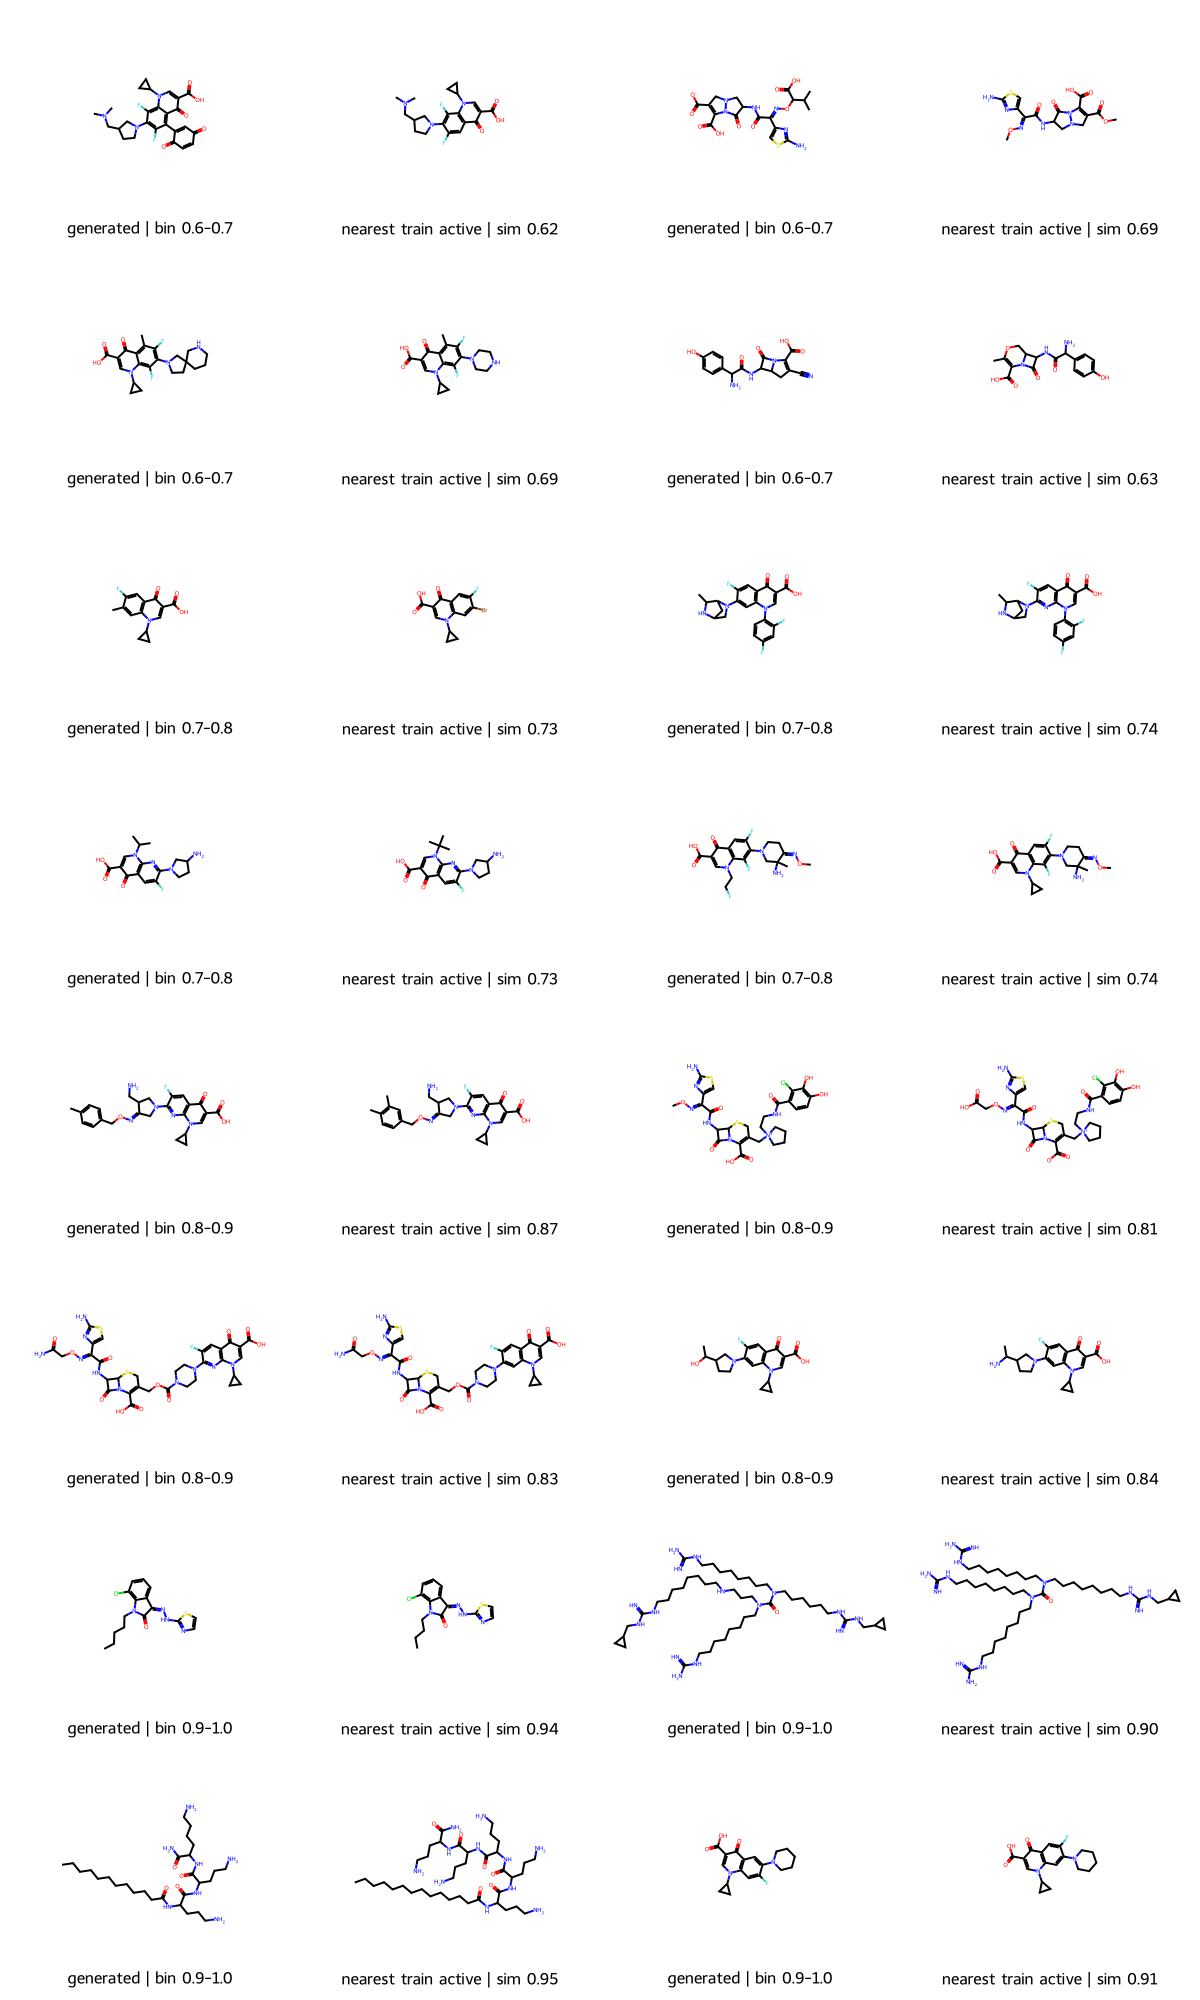

AttributeError: 'Image' object has no attribute 'save'

In [2]:
import os, numpy as np, pandas as pd
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import rdFingerprintGenerator, Draw
from IPython.display import display
RDLogger.DisableLog('rdApp.*')

# Cell 2 resets this to the temp_ignored folder, so set the correct file again
P['gen10'] = f'{BASE}/results/day10/gen_T1.0_unique.csv'
assert os.path.exists(P['gen10']) and 'temp_ignored' not in P['gen10']

def canon(s):
    m = Chem.MolFromSmiles(s)
    return Chem.MolToSmiles(m) if m is not None else None

def read_smi(path):
    with open(path) as f:
        return [ln.split()[0] for ln in f if ln.strip()]

core_set   = {canon(s) for s in read_smi(P['core'])}   - {None}
border_set = {canon(s) for s in read_smi(P['border'])} - {None}
known_list = sorted(core_set | border_set)
print(f"core {len(core_set)} | border {len(border_set)} | all known {len(known_list)} (expect 3,362 / 818 / 4,180)")

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
known_fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in known_list]

g = pd.read_csv(P['gen10'])
print("generated rows:", len(g), "(expect 39,201)")

rng = np.random.default_rng(42)
mols, legends = [], []
for lo, hi in [(0.6, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 1.0)]:
    sub = g[(g.maxsim_all >= lo) & (g.maxsim_all < hi)]
    for i in rng.choice(sub.index, 4, replace=False):
        m = Chem.MolFromSmiles(g.loc[i, 'smiles'])
        sims = np.array(DataStructs.BulkTanimotoSimilarity(gen.GetFingerprint(m), known_fps))
        j = sims.argmax()
        mols += [m, Chem.MolFromSmiles(known_list[j])]
        legends += [f'generated | bin {lo}-{hi}', f'nearest train active | sim {sims[j]:.2f}']

img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 250), legends=legends)
display(img)
os.makedirs(f'{BASE}/results/day12', exist_ok=True)
img.save(f'{BASE}/results/day12/nearest_train_pairs_by_similarity.png')
print("saved image")

In [3]:
path = f'{BASE}/results/day12/nearest_train_pairs_by_similarity.png'
with open(path, 'wb') as f:
    f.write(img.data)
print("saved:", path, "|", os.path.getsize(path)//1024, "KB")

saved: /content/drive/MyDrive/kpneu_project/results/day12/nearest_train_pairs_by_similarity.png | 287 KB


In [4]:
split = pd.read_csv(P['split'])
X_all = np.load(P['npy']).astype(np.float32)
print(split['split_scaffold'].value_counts())
mask = split['split_scaffold'].astype(str).str.lower().eq('train').values
assert mask.sum() == 11366, "check the labels printed above"

Xt = X_all[mask]
yt = split.loc[mask, 'active'].astype(int).values
cnt = Xt.sum(1)
n = len(Xt)
nn_sim = np.zeros(n, dtype=np.float32)
nn_idx = np.zeros(n, dtype=int)

for s in range(0, n, 1000):
    e = min(s + 1000, n)
    inter = Xt[s:e] @ Xt.T
    sim = inter / np.maximum(cnt[s:e, None] + cnt[None, :] - inter, 1)
    sim[np.arange(e - s), np.arange(s, e)] = -1      # exclude self
    nn_idx[s:e] = sim.argmax(1)
    nn_sim[s:e] = sim.max(1)

same = (yt == yt[nn_idx])
nb_active = yt[nn_idx] == 1
bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
cut = pd.cut(nn_sim, bins, right=False)

df = pd.DataFrame({'bin': cut, 'same_label': same,
                   'query_active': yt == 1, 'nb_active': nb_active})
out = df.groupby('bin', observed=True).agg(n=('same_label', 'size'),
                                           same_label_pct=('same_label', lambda x: round(x.mean() * 100, 1)))
act = df[df.query_active].groupby('bin', observed=True)['nb_active'].agg(
    n_active_queries='size', neighbour_also_active_pct=lambda x: round(x.mean() * 100, 1))
print(out.join(act))

print("\nNearest-neighbour similarity within train (percentiles 10/25/50/75/90):",
      np.round(np.percentile(nn_sim, [10, 25, 50, 75, 90]), 2))
print("Share of train molecules with a neighbour >= 0.8:", round((nn_sim >= 0.8).mean() * 100, 1), "%")
print("Overall base rate active:", round(yt.mean() * 100, 1), "%")

split_scaffold
train    11366
test      1422
val       1420
Name: count, dtype: int64
               n  same_label_pct  n_active_queries  neighbour_also_active_pct
bin                                                                          
[0.0, 0.4)   236            69.5                59                       25.4
[0.4, 0.5)   179            77.7                41                       53.7
[0.5, 0.6)   401            80.5                97                       61.9
[0.6, 0.7)  1052            82.8               340                       75.9
[0.7, 0.8)  2950            84.6              1114                       81.4
[0.8, 0.9)  4341            84.4              2093                       84.7
[0.9, 1.0)  2207            82.3              1083                       79.5

Nearest-neighbour similarity within train (percentiles 10/25/50/75/90): [0.64 0.74 0.82 0.88 1.  ]
Share of train molecules with a neighbour >= 0.8: 57.6 %
Overall base rate active: 42.5 %


In [6]:
import numpy as np, pandas as pd

split = pd.read_csv(P['split'])
X_all = np.load(P['npy']).astype(np.float32)

lab = split['split_scaffold'].astype(str).str.lower().values
Xtr = X_all[lab == 'train']
cnt_tr = Xtr.sum(1)

def max_sim_to_train(Xq, exclude_self=False):
    cnt_q = Xq.sum(1)
    out = np.zeros(len(Xq), dtype=np.float32)
    for s in range(0, len(Xq), 1000):
        e = min(s + 1000, len(Xq))
        inter = Xq[s:e] @ Xtr.T
        sim = inter / np.maximum(cnt_q[s:e, None] + cnt_tr[None, :] - inter, 1)
        if exclude_self:
            sim[np.arange(e - s), np.arange(s, e)] = -1
        out[s:e] = sim.max(1)
    return out

results = {
    'train -> train': max_sim_to_train(Xtr, exclude_self=True),
    'val -> train':   max_sim_to_train(X_all[lab == 'val']),
    'test -> train':  max_sim_to_train(X_all[lab == 'test']),
}

rows = []
for name, v in results.items():
    p10, p25, p50, p75, p90 = np.percentile(v, [10, 25, 50, 75, 90])
    rows.append({'comparison': name, 'n': len(v),
                 'p10': round(p10, 2), 'p25': round(p25, 2), 'median': round(p50, 2),
                 'p75': round(p75, 2), 'p90': round(p90, 2),
                 'pct_ge_0.8': round((v >= 0.8).mean() * 100, 1),
                 'pct_lt_0.5': round((v < 0.5).mean() * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

    comparison     n  p10  p25  median  p75  p90  pct_ge_0.8  pct_lt_0.5
train -> train 11366 0.64 0.74    0.82 0.88 1.00        57.6         3.7
  val -> train  1420 0.41 0.52    0.67 0.77 0.84        18.6        21.7
 test -> train  1422 0.36 0.52    0.67 0.76 0.85        17.0        21.5


In [15]:
import numpy as np, pandas as pd, joblib
from sklearn.metrics import roc_auc_score

MODEL_PATH = '/content/drive/MyDrive/kpneu_project/models/rf_scaffold_v1.joblib'
bundle = joblib.load(MODEL_PATH)

# The file is a dict: find the object that can predict
if isinstance(bundle, dict):
    print("Keys in file:", list(bundle.keys()))
    rf = next(v for v in bundle.values() if hasattr(v, 'predict_proba'))
else:
    rf = bundle
print("Model type:", type(rf).__name__)

split = pd.read_csv(P['split'])
X_all = np.load(P['npy']).astype(np.float32)
lab = split['split_scaffold'].astype(str).str.lower().values
y_all = split['active'].astype(int).values

Xtr = X_all[lab == 'train']
cnt_tr = Xtr.sum(1)

def max_sim_to_train(Xq):
    cnt_q = Xq.sum(1)
    out = np.zeros(len(Xq), dtype=np.float32)
    for s in range(0, len(Xq), 1000):
        e = min(s + 1000, len(Xq))
        inter = Xq[s:e] @ Xtr.T
        sim = inter / np.maximum(cnt_q[s:e, None] + cnt_tr[None, :] - inter, 1)
        out[s:e] = sim.max(1)
    return out

def auc_by_similarity(name):
    m = lab == name
    Xq, yq = X_all[m], y_all[m]
    sim = max_sim_to_train(Xq)
    prob = rf.predict_proba(Xq)[:, 1]

    print(f"\n{name}: overall AUC = {roc_auc_score(yq, prob):.3f}  (n={len(yq)})")
    bins = [0, 0.5, 0.7, 1.0001]
    labels = ['<0.5', '0.5-0.7', '>=0.7']
    grp = pd.cut(sim, bins, labels=labels, right=False)

    rows = []
    for g in labels:
        sel = (grp == g)
        n, n_act = int(sel.sum()), int(yq[sel].sum())
        auc = roc_auc_score(yq[sel], prob[sel]) if 0 < n_act < n else np.nan
        acc = ((prob[sel] >= 0.5) == yq[sel]).mean() if n else np.nan
        rows.append({'similarity_to_train': g, 'n': n, 'n_active': n_act,
                     'AUC': round(auc, 3), 'accuracy@0.5': round(acc, 3)})
    print(pd.DataFrame(rows).to_string(index=False))

auc_by_similarity('test')
auc_by_similarity('val')

Keys in file: ['model', 'ad_threshold', 'cutoff_ug_mL', 'features', 'seed', 'train_split', 'sklearn']
Model type: RandomForestClassifier

test: overall AUC = 0.867  (n=1422)
similarity_to_train   n  n_active   AUC  accuracy@0.5
               <0.5 306        95 0.714         0.703
            0.5-0.7 549       203 0.839         0.763
              >=0.7 567       288 0.925         0.848

val: overall AUC = 0.898  (n=1420)
similarity_to_train   n  n_active   AUC  accuracy@0.5
               <0.5 308        57 0.707         0.805
            0.5-0.7 489       143 0.879         0.828
              >=0.7 623       320 0.926         0.846


In [16]:
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

split = pd.read_csv(P['split'])
print("Columns:", list(split.columns))

# find the SMILES column
cands = [c for c in split.columns if 'smiles' in c.lower()]
assert cands, "No SMILES column found: paste the column list above and I'll adjust"
smi_col = cands[0]
print("Using SMILES column:", smi_col)

lab = split['split_scaffold'].astype(str).str.lower().values
tr = split[lab == 'train'].copy()

def n_rot(s):
    m = Chem.MolFromSmiles(str(s))
    return rdMolDescriptors.CalcNumRotatableBonds(m) if m else np.nan

tr['rot'] = tr[smi_col].map(n_rot)
tr = tr.dropna(subset=['rot'])

def summarize(name, d):
    r = d['rot']
    return {'group': name, 'n': len(d),
            'median': r.median(), 'p90': r.quantile(0.9),
            '%>10': round((r > 10).mean() * 100, 1),
            '%>12': round((r > 12).mean() * 100, 1)}

rows = [summarize('train all', tr),
        summarize('train actives', tr[tr['active'] == 1]),
        summarize('train inactives', tr[tr['active'] == 0])]

# core actives (MIC <= 8), if an MIC column exists
mic_cols = [c for c in tr.columns if 'mic' in c.lower() or 'value' in c.lower()]
print("Possible MIC columns:", mic_cols)

print(pd.DataFrame(rows).to_string(index=False))

# activity rate by rotatable-bond count
tr['rot_bin'] = pd.cut(tr['rot'], [-1, 3, 6, 8, 10, 12, 100],
                       labels=['0-3', '4-6', '7-8', '9-10', '11-12', '>12'])
print(tr.groupby('rot_bin', observed=True)['active']
        .agg(n='size', pct_active=lambda x: round(x.mean() * 100, 1)))

Columns: ['can_smiles', 'mic_ugml', 'relation', 'n_meas', 'fold_range', 'conflict', 'mol_chembl_id', 'suspect_high', 'suspect_low', 'n_stereo', 'n_undefined', 'stereo_flag', 'assay_types', 'strains', 'n_assays', 'n_strains', 'strain_known', 'multi_strain', 'label', 'active', 'MW', 'logP', 'TPSA', 'HBD', 'HBA', 'scaffold', 'split_scaffold', 'split_random', 'source']
Using SMILES column: can_smiles
Possible MIC columns: ['mic_ugml']
          group     n  median  p90  %>10  %>12
      train all 11366     5.0 12.0  13.5   9.4
  train actives  4827     5.0 11.0  12.6   8.5
train inactives  6539     5.0 13.0  14.2  10.0
            n  pct_active
rot_bin                  
0-3      2883        42.2
4-6      4401        43.8
7-8      1711        42.3
9-10      831        42.1
11-12     476        42.2
>12      1064        38.3


In [19]:
import joblib, sklearn, numpy as np, pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

print("sklearn:", sklearn.__version__, "(must be 1.6.1)")
obj = joblib.load(P['model'])
for k, v in obj.items():
    print(f"{k!r}: {repr(v)[:120]}")

split = pd.read_csv(P['split'])
fp_saved = np.load(P['npy'])
print("Row counts match:", len(split) == fp_saved.shape[0])
g = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
bad = sum(not np.array_equal(g.GetFingerprintAsNumPy(Chem.MolFromSmiles(split.loc[i, 'can_smiles'])).astype(np.uint8),
                             fp_saved[i].astype(np.uint8)) for i in range(300))
print("Fingerprint mismatches in first 300 rows:", bad)

sklearn: 1.6.1 (must be 1.6.1)
'model': RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)
'ad_threshold': 0.3
'cutoff_ug_mL': 16
'features': 'Morgan r2 2048'
'seed': 42
'train_split': 'scaffold'
'sklearn': '1.6.1'
Row counts match: True
Fingerprint mismatches in first 300 rows: 0


In [21]:
from google.colab import drive
drive.mount('/content/drive')
import os

BASE = '/content/drive/MyDrive/kpneu_project'
assert os.path.isdir(BASE), "BASE folder not found"

P = {
    'model':  f'{BASE}/models/rf_scaffold_v1.joblib',
    'npy':    f'{BASE}/data/features/morgan_r2_2048_v1.npy',
    'split':  f'{BASE}/data/splits/split_v1.csv',
    'gen10':  f'{BASE}/results/day10/gen_T1.0_unique.csv',
    'gen12':  f'{BASE}/results/day10/gen_T1.2_unique.csv',
    'core':   f'{BASE}/data/finetune/core_unique_v2.smi',
    'border': f'{BASE}/data/finetune/border_unique_v1.smi',
}
for k, v in P.items():
    print(f"{k:7s} exists={os.path.exists(v)}  {v}")
    assert os.path.exists(v), f"missing: {k}"
assert 'temp_ignored' not in P['gen10'] and 'temp_ignored' not in P['gen12']

# ---------- settings (change only here) ----------
POOLS    = ['gen10']   # add 'gen12' for the optional T=1.2 pool
NEAR_DUP = 0.80        # provisional, to confirm with Parth
MW_MIN, MW_MAX = 150, 700
ROTB_MAX = 12          # provisional, to confirm with Parth (was 10 in first pass)
OUTDIR = f'{BASE}/results/day12_v2'
# --------------------------------------------------
os.makedirs(OUTDIR, exist_ok=True)
print("\nSettings:", dict(POOLS=POOLS, NEAR_DUP=NEAR_DUP, MW=(MW_MIN, MW_MAX), ROTB_MAX=ROTB_MAX, OUTDIR=OUTDIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
model   exists=True  /content/drive/MyDrive/kpneu_project/models/rf_scaffold_v1.joblib
npy     exists=True  /content/drive/MyDrive/kpneu_project/data/features/morgan_r2_2048_v1.npy
split   exists=True  /content/drive/MyDrive/kpneu_project/data/splits/split_v1.csv
gen10   exists=True  /content/drive/MyDrive/kpneu_project/results/day10/gen_T1.0_unique.csv
gen12   exists=True  /content/drive/MyDrive/kpneu_project/results/day10/gen_T1.2_unique.csv
core    exists=True  /content/drive/MyDrive/kpneu_project/data/finetune/core_unique_v2.smi
border  exists=True  /content/drive/MyDrive/kpneu_project/data/finetune/border_unique_v1.smi

Settings: {'POOLS': ['gen10'], 'NEAR_DUP': 0.8, 'MW': (150, 700), 'ROTB_MAX': 12, 'OUTDIR': '/content/drive/MyDrive/kpneu_project/results/day12_v2'}


In [22]:
import pandas as pd, numpy as np, os
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

funnel = []
def log(step, d):
    funnel.append({'step': step, 'n_remaining': len(d)})
    print(f"{step:60s}{len(d):>9,}")

frames = []
for key in POOLS:
    d = pd.read_csv(P[key])
    d = d.rename(columns={'maxsim_core': 'maxsim_core_file', 'maxsim_all': 'maxsim_all_file'})
    d['pool'] = {'gen10': 'T1.0', 'gen12': 'T1.2'}[key]
    frames.append(d)
    print(key, "rows:", len(d))
pool = pd.concat(frames, ignore_index=True)
log('Start: valid unique molecules from file(s)', pool)

def canon(s):
    m = Chem.MolFromSmiles(s)
    return Chem.MolToSmiles(m) if m is not None else None

pool['can'] = pool['smiles'].map(canon)
pool = pool[pool['can'].notna()].copy()
log('Valid and canonical (RDKit re-parse)', pool)
pool = pool.drop_duplicates('can', keep='first').reset_index(drop=True)
log('Deduplicated (canonical SMILES)', pool)

gen10 rows: 39201
Start: valid unique molecules from file(s)                     39,201
Valid and canonical (RDKit re-parse)                           39,201
Deduplicated (canonical SMILES)                                39,201


In [23]:
def read_smi(path):
    with open(path) as f:
        return [ln.split()[0] for ln in f if ln.strip()]

core_set   = {canon(s) for s in read_smi(P['core'])}   - {None}
border_set = {canon(s) for s in read_smi(P['border'])} - {None}
known_set  = core_set | border_set
print(f"core {len(core_set)} | border {len(border_set)} | all known {len(known_set)} (expect 3,362 / 818 / 4,180)")

known_list = sorted(known_set)
is_core = np.array([s in core_set for s in known_list])
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
known_fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in known_list]

max_all, max_core = [], []
for s in pool['can']:
    sims = np.array(DataStructs.BulkTanimotoSimilarity(gen.GetFingerprint(Chem.MolFromSmiles(s)), known_fps))
    max_all.append(sims.max())
    max_core.append(sims[is_core].max())
pool['maxsim_all'] = max_all
pool['maxsim_core'] = max_core
pool['exact_train'] = pool['can'].isin(known_set)

chk = (pool['maxsim_all'] - pool['maxsim_all_file']).abs().dropna()
print("Max abs difference vs Day 10 maxsim_all:", round(chk.max(), 4))

bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
print("\nMax similarity to known train actives (novelty distribution):")
print(pd.cut(pool['maxsim_all'], bins, right=False).value_counts().sort_index())
print("exact copies:", int(pool['exact_train'].sum()))
for t in [0.7, 0.8, 0.9]:
    print(f"  max sim >= {t}: {(pool['maxsim_all'] >= t).sum():,}")

pool = pool[~pool['exact_train']].copy()
log('Removed exact matches to known train actives', pool)
pool = pool[pool['maxsim_all'] < NEAR_DUP].copy()
log(f'Removed near-duplicates (max Tanimoto >= {NEAR_DUP})', pool)

core 3362 | border 818 | all known 4180 (expect 3,362 / 818 / 4,180)
Max abs difference vs Day 10 maxsim_all: 0.0

Max similarity to known train actives (novelty distribution):
maxsim_all
[0.0, 0.4)    10502
[0.4, 0.5)     5158
[0.5, 0.6)     5929
[0.6, 0.7)     6321
[0.7, 0.8)     5529
[0.8, 0.9)     3239
[0.9, 1.0)     2523
Name: count, dtype: int64
exact copies: 1803
  max sim >= 0.7: 11,291
  max sim >= 0.8: 5,762
  max sim >= 0.9: 2,523
Removed exact matches to known train actives                   37,398
Removed near-duplicates (max Tanimoto >= 0.8)                  33,439


In [24]:
def props(s):
    m = Chem.MolFromSmiles(s)
    return (Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
            Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
            rdMolDescriptors.CalcNumRotatableBonds(m), m.GetNumHeavyAtoms())

pc = pd.DataFrame([props(s) for s in pool['can']],
                  columns=['MW', 'logP', 'TPSA', 'HBD', 'HBA', 'RotB', 'heavy_atoms'], index=pool.index)
pool = pd.concat([pool.drop(columns=[c for c in pc.columns if c in pool.columns]), pc], axis=1)

pool['ro5_violations'] = ((pool.MW > 500).astype(int) + (pool.logP > 5).astype(int)
                          + (pool.HBD > 5).astype(int) + (pool.HBA > 10).astype(int))

pool = pool[(pool.MW >= MW_MIN) & (pool.MW <= MW_MAX)].copy()
log(f'Property window: MW {MW_MIN}-{MW_MAX}', pool)
pool = pool[pool.RotB <= ROTB_MAX].copy()
log(f'Property window: rotatable bonds <= {ROTB_MAX}', pool)

print("\nRo5 violations among survivors (report only, no filtering):")
print(pool['ro5_violations'].value_counts().sort_index())
print("Ro5 version A (0 violations):", int((pool.ro5_violations == 0).sum()),
      "| version B (<=1 violation):", int((pool.ro5_violations <= 1).sum()))

Property window: MW 150-700                                    31,711
Property window: rotatable bonds <= 12                         30,055

Ro5 violations among survivors (report only, no filtering):
ro5_violations
0    20361
1     6152
2     3025
3      517
Name: count, dtype: int64
Ro5 version A (0 violations): 20361 | version B (<=1 violation): 26513


In [25]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

def make_cat(c):
    p = FilterCatalogParams(); p.AddCatalog(c); return FilterCatalog(p)

pains = make_cat(FilterCatalogParams.FilterCatalogs.PAINS)
brenk = make_cat(FilterCatalogParams.FilterCatalogs.BRENK)

def alerts(cat, m):
    return ';'.join(sorted({e.GetDescription() for e in cat.GetMatches(m)}))

mols = [Chem.MolFromSmiles(s) for s in pool['can']]
pool['pains_alerts'] = [alerts(pains, m) for m in mols]
pool['brenk_alerts'] = [alerts(brenk, m) for m in mols]

pool_before_alerts = pool.copy()
pool_before_alerts.to_csv(f'{OUTDIR}/day12_before_alerts.csv', index=False)

pool = pool[pool['pains_alerts'] == ''].copy()
log('Removed PAINS', pool)
pool = pool[pool['brenk_alerts'] == ''].copy()
log('Removed Brenk', pool)

print("\nMost common Brenk alerts among removed molecules:")
removed = pool_before_alerts[pool_before_alerts['brenk_alerts'] != '']
print(removed['brenk_alerts'].str.split(';').explode().value_counts().head(10))

Removed PAINS                                                  28,293
Removed Brenk                                                  13,203

Most common Brenk alerts among removed molecules:
brenk_alerts
Oxygen-nitrogen_single_bond    6387
imine_1                        5132
Aliphatic_long_chain           2248
nitro_group                    1749
aniline                        1603
Thiocarbonyl_group             1596
Michael_acceptor_1             1012
triple_bond                    1002
imine_2                         801
quaternary_nitrogen_1           764
Name: count, dtype: int64


In [26]:
import sys, urllib.request
try:
    from rdkit.Chem import RDConfig
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
    import sascorer
    print("sascorer loaded from RDKit Contrib")
except Exception as e:
    print("Contrib not available, downloading sascorer:", e)
    os.makedirs('/content/sa', exist_ok=True)
    url = 'https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/'
    for f in ['sascorer.py', 'fpscores.pkl.gz']:
        urllib.request.urlretrieve(url + f, f'/content/sa/{f}')
    sys.path.insert(0, '/content/sa')
    import sascorer

pool['sa_score'] = [sascorer.calculateScore(Chem.MolFromSmiles(s)) for s in pool['can']]
print(pool['sa_score'].describe().round(2))

pool = pool.reset_index(drop=True)
pool.to_csv(f'{OUTDIR}/day12_survivors.csv', index=False)
ft = pd.DataFrame(funnel)
ft['removed_at_step'] = (-ft['n_remaining'].diff()).fillna(0).astype(int)
ft.to_csv(f'{OUTDIR}/day12_funnel.csv', index=False)
print("\nFUNNEL")
print(ft.to_string(index=False))
print("\nSaved to:", OUTDIR)

sascorer loaded from RDKit Contrib
count    13203.00
mean         3.25
std          0.79
min          1.43
25%          2.67
50%          3.14
75%          3.70
max          7.80
Name: sa_score, dtype: float64

FUNNEL
                                         step  n_remaining  removed_at_step
   Start: valid unique molecules from file(s)        39201                0
         Valid and canonical (RDKit re-parse)        39201                0
              Deduplicated (canonical SMILES)        39201                0
 Removed exact matches to known train actives        37398             1803
Removed near-duplicates (max Tanimoto >= 0.8)        33439             3959
                  Property window: MW 150-700        31711             1728
       Property window: rotatable bonds <= 12        30055             1656
                                Removed PAINS        28293             1762
                                Removed Brenk        13203            15090

Saved to: /content/dr

In [27]:
n = len(pool)
print(f"Survivors: {n:,}")
for t in [0.6, 0.7, 0.8]:
    print(f"  maxsim_all < {t}: {int((pool.maxsim_all < t).sum()):,} ({(pool.maxsim_all < t).mean()*100:.1f}%)")

core_mols = [Chem.MolFromSmiles(s) for s in sorted(core_set)]
tp = np.array([pains.HasMatch(m) for m in core_mols])
tb = np.array([brenk.HasMatch(m) for m in core_mols])
print(f"\nTraining core actives (n={len(core_mols):,}): PAINS {tp.mean()*100:.1f}% | Brenk {tb.mean()*100:.1f}% | either {(tp|tb).mean()*100:.1f}%")
gp = pool_before_alerts['pains_alerts'] != ''
gb = pool_before_alerts['brenk_alerts'] != ''
print(f"Generated before alert removal (n={len(pool_before_alerts):,}): PAINS {gp.mean()*100:.1f}% | Brenk {gb.mean()*100:.1f}% | either {(gp|gb).mean()*100:.1f}%")

Survivors: 13,203
  maxsim_all < 0.6: 7,858 (59.5%)
  maxsim_all < 0.7: 10,580 (80.1%)
  maxsim_all < 0.8: 13,203 (100.0%)

Training core actives (n=3,362): PAINS 5.5% | Brenk 57.0% | either 57.6%
Generated before alert removal (n=30,055): PAINS 5.9% | Brenk 54.9% | either 56.1%
